# SHAP Analysis: Term-Deposit Outreach Ranker (BAN6800, Module 4)
This notebook explains the proposed model (`models/stratified_no_macro_gboost.joblib`, Gradient Boosting without the five economic indicators) on the stratified hold-out test set. SHAP values are in log-odds: positive values push a customer's score up, negative values push it down. It also contrasts the proposed model with the full-feature model, which includes the economic indicators.

**What SHAP can and cannot say.** It describes what the model relies on. It does not show that changing a feature would change a customer's behaviour, and correlated features (for example channel and month, which partly reflect the campaign period) share credit unpredictably.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "m4")
import numpy as np, pandas as pd, joblib, shap
import matplotlib.pyplot as plt
from common import load, split_stratified, CAT, NUM, FEATURES

MACRO = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
FEATS = CAT + [c for c in NUM if c not in MACRO]
df = load()
train, test = split_stratified(df)
print("test rows:", len(test), "| subscribers:", int(test["y"].sum()))

test rows: 8236 | subscribers: 928


In [2]:
def explain(path, feats):
    pipe = joblib.load(path)
    prep, clf = pipe.named_steps["prep"], pipe.named_steps["clf"]
    X = prep.transform(test[feats])
    X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
    names = [n.split("__", 1)[-1] for n in prep.get_feature_names_out()]
    ex = shap.TreeExplainer(clf)
    sv = ex.shap_values(X)
    sv = sv[1] if isinstance(sv, list) else sv
    base = float(np.ravel(ex.expected_value)[0])
    return pipe, X, names, sv, base

pipe, X, names, sv, base = explain("models/stratified_no_macro_gboost.joblib", FEATS)
imp = pd.Series(np.abs(sv).mean(axis=0), index=names).sort_values(ascending=False)
print("Proposed model: top 12 features by mean |SHAP| (log-odds)")
imp.head(12).round(4)

Proposed model: top 12 features by mean |SHAP| (log-odds)


contact_cellular                                0.2478
missingindicator_days_since_previous_contact    0.1517
contact_telephone                               0.1239
age                                             0.1210
month_jun                                       0.1076
default_no                                      0.1023
month_apr                                       0.0931
month_oct                                       0.0508
month_mar                                       0.0481
education_university.degree                     0.0380
month_sep                                       0.0327
poutcome_success                                0.0322
dtype: float64

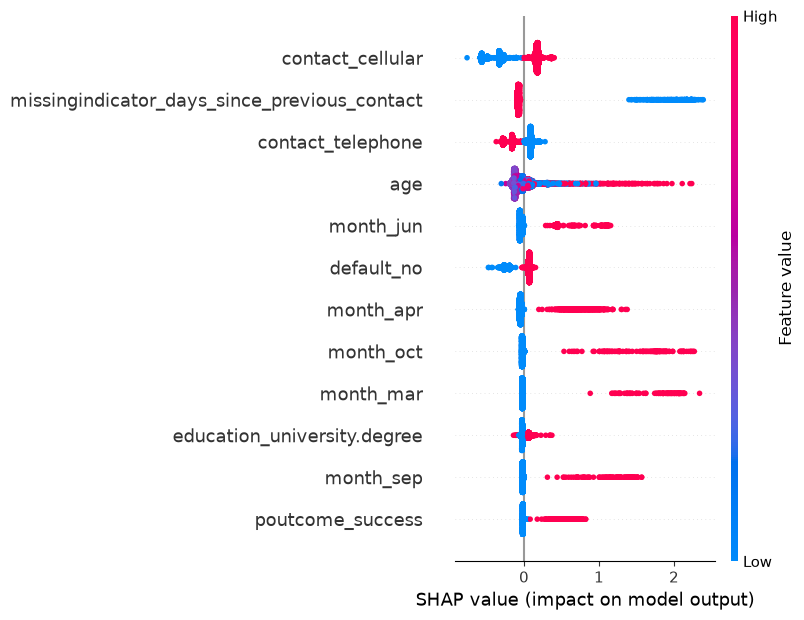

In [3]:
shap.summary_plot(sv, X, feature_names=names, max_display=12)

### Your interpretation: global importance (proposed model)

The model relies most on how the customer was contacted (mobile phone or landline), whether a previous contact is on record, and age, with the months June and April also carrying weight. The bank chooses the channel and the timing, but it does not control a customer's age or history. These are patterns in the data and not proof of cause: channel and month partly reflect how the campaigns were run, so moving a customer to a mobile phone or calling in June would not necessarily change their decision.

Full model (with economic indicators): top 8 features by mean |SHAP|


nr.employed                                     0.3698
euribor3m                                       0.1349
cons.conf.idx                                   0.1190
contact_telephone                               0.1056
missingindicator_days_since_previous_contact    0.0686
age                                             0.0686
contact_cellular                                0.0617
emp.var.rate                                    0.0583
dtype: float64

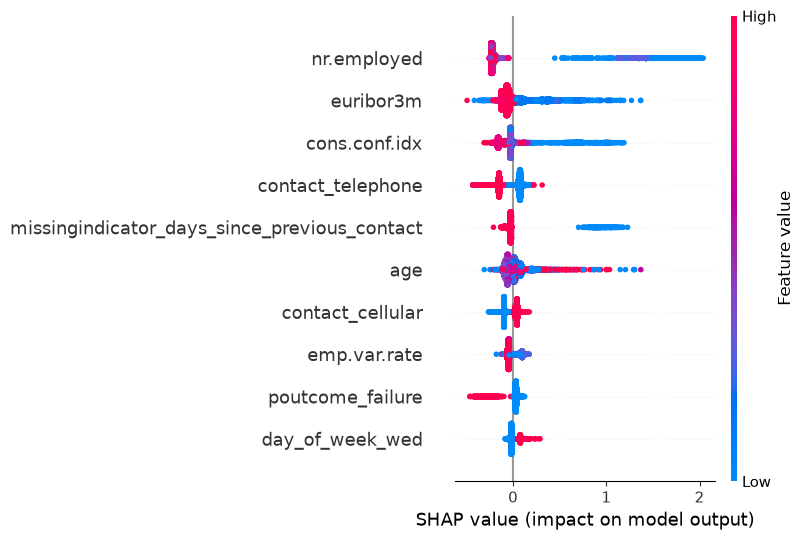

In [4]:
full_pipe, Xf, names_f, sv_f, base_f = explain("models/stratified_gboost.joblib", FEATURES)
imp_f = pd.Series(np.abs(sv_f).mean(axis=0), index=names_f).sort_values(ascending=False)
print("Full model (with economic indicators): top 8 features by mean |SHAP|")
display(imp_f.head(8).round(4))
shap.summary_plot(sv_f, Xf, feature_names=names_f, max_display=10)

### Your interpretation: why the economic indicators were removed

The full model relied most on the employment level, the Euribor interest rate and consumer confidence. These numbers are the same for every customer contacted on the same day, so they tell the model which campaign period a call belonged to but not which customer is more likely to subscribe. They would not help a manager choose between two customers on a given day. The full model reached 73.5% capture and removing the indicators gives 67.2%. I treat 73.5% as an upper bound and 67.2% as the realistic figure.

top-ranked customer | predicted probability: 0.944
{'age': 59, 'job': 'admin.', 'marital': 'married', 'education': 'university.degree', 'contact': 'cellular', 'month': 'sep', 'poutcome': 'success', 'previous': 1}
   whether a previous-contact date is on record: +2.28 log-odds (raises the score)
   month = sep: +1.27 log-odds (raises the score)
   previous campaign was a success: +0.56 log-odds (raises the score)
   age: +0.44 log-odds (raises the score)


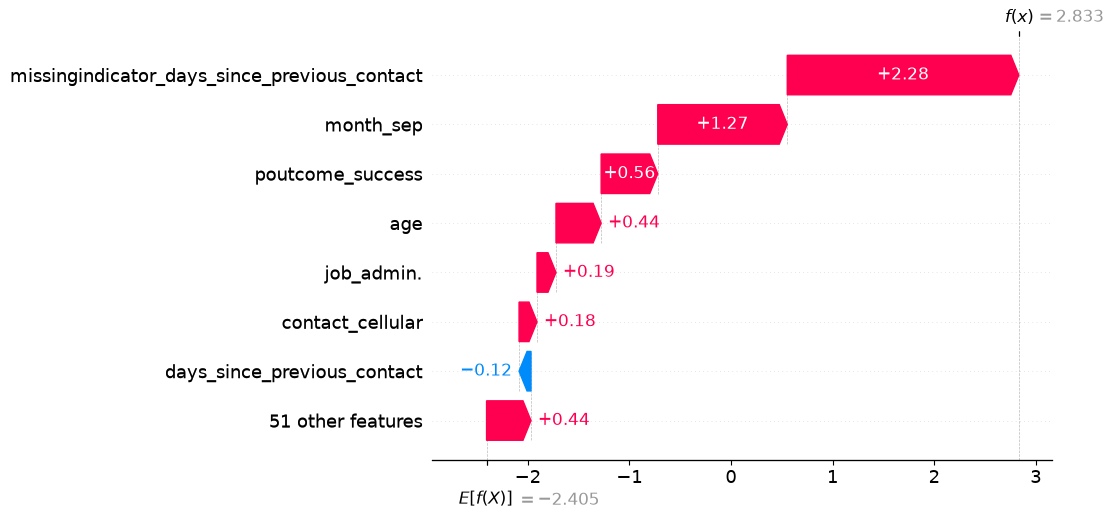

borderline customer (rank at the 30% cut) | predicted probability: 0.09
{'age': 42, 'job': 'admin.', 'marital': 'married', 'education': 'university.degree', 'contact': 'cellular', 'month': 'nov', 'poutcome': 'nonexistent', 'previous': 0}
   contacted on a mobile phone: +0.18 log-odds (raises the score)
   age: -0.15 log-odds (lowers the score)
   contacted on a landline: +0.09 log-odds (raises the score)
   whether a previous-contact date is on record: -0.08 log-odds (lowers the score)


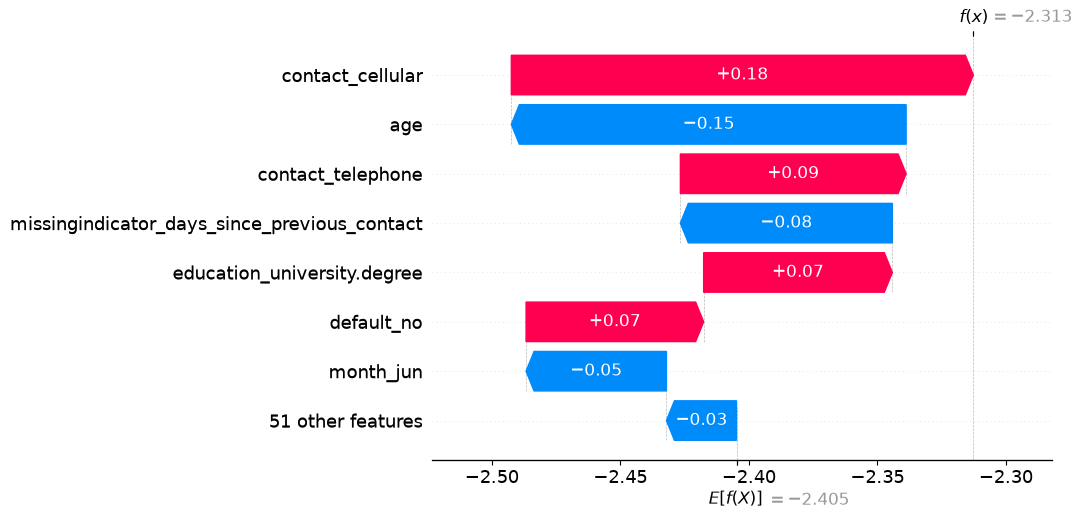

bottom-ranked customer | predicted probability: 0.024
{'age': 37, 'job': 'blue-collar', 'marital': 'divorced', 'education': 'basic.4y', 'contact': 'telephone', 'month': 'may', 'poutcome': 'nonexistent', 'previous': 0}
   contacted on a mobile phone: -0.28 log-odds (lowers the score)
   no credit default on record: -0.19 log-odds (lowers the score)
   contacted on a landline: -0.16 log-odds (lowers the score)
   age: -0.14 log-odds (lowers the score)


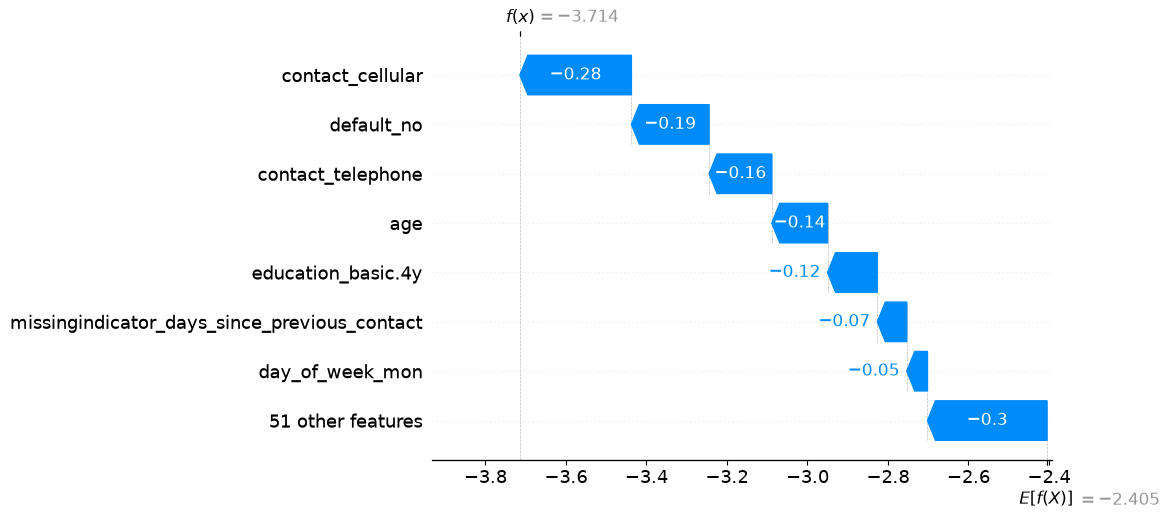

In [5]:
PLAIN = {
    "contact_cellular": "contacted on a mobile phone",
    "contact_telephone": "contacted on a landline",
    "missingindicator_days_since_previous_contact": "whether a previous-contact date is on record",
    "age": "age",
    "default_no": "no credit default on record",
    "poutcome_success": "previous campaign was a success",
    "poutcome_failure": "previous campaign failed",
}
def plain(n):
    return PLAIN.get(n, n.replace("_", " = ", 1) if "_" in n else n)

score = pipe.predict_proba(test[FEATS])[:, 1]
order = np.argsort(-score, kind="stable")
cut = int(round(len(score) * 0.30))
picks = {"top-ranked customer": order[0], "borderline customer (rank at the 30% cut)": order[cut - 1], "bottom-ranked customer": order[-1]}
for label, i in picks.items():
    row = test.iloc[i]
    print("=" * 70)
    print(label, "| predicted probability:", round(float(score[i]), 3))
    print(row[["age", "job", "marital", "education", "contact", "month", "poutcome", "previous"]].to_dict())
    top = pd.Series(sv[i], index=names).sort_values(key=np.abs, ascending=False).head(4)
    for n, v in top.items():
        print(f"   {plain(n)}: {v:+.2f} log-odds ({'raises' if v > 0 else 'lowers'} the score)")
    shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=base, feature_names=names), max_display=8)

### Your interpretation: local explanations

For the top-ranked customer (probability about 0.94), having a previous contact on record added the most, followed by September, the earlier campaign success and age. This is the kind of customer a manager would expect to approach. The borderline customer (about 0.09) has small pushes in both directions, with mobile contact adding a little and age taking a little away, so the position at the cut-off is close to a coin toss and the manager's knowledge of the customer should carry more weight than the score. For the bottom-ranked customer (about 0.02), contact channel, credit default status and age all push the score down. A manager can use these explanations to see why a customer ranks where they do, but should not read them as reasons the customer will or will not subscribe, and a low score is not a reason to ignore a customer whose circumstances have changed.

In [6]:
age_idx = names.index("age")
t = pd.DataFrame({"age_band": test["age_band"].values, "age_shap": sv[:, age_idx]})
print("Average SHAP contribution of the age feature, by age band (log-odds)")
t.groupby("age_band")["age_shap"].agg(["mean", "size"]).round(3)

Average SHAP contribution of the age feature, by age band (log-odds)


,mean,size
age_band,,
17-24,0.372,214
25-34,0.031,2720
35-44,-0.117,2734
45-54,-0.033,1727
55-64,0.182,721
65+,1.041,120


### Your interpretation: age and fairness

The average age contribution is highest in the 65+ band (+1.04 log-odds) and lowest in the 35-44 band (-0.12). This fits the fairness results. Before mitigation, 81% of customers aged 17-24 and every customer aged 65+ were selected, against 16% of those aged 35-44 and 19% of those aged 45-54, so the model favours the youngest and oldest customers, who also subscribe more often in this data. Removing age, marital status and education from the model cut the number of age bands beyond the 10-point recall gap from five to two, but the 17-24 and 65+ bands were still over-selected, because other features such as job and previous-campaign outcome still carry information about age.

### Limitations of this analysis
SHAP explains the model's behaviour on this data, not why customers subscribe. Channel, month and previous-campaign status partly reflect when and how the bank ran its campaigns, so their contributions mix customer behaviour with campaign design. Contributions are computed on the stratified test set only. The waterfall plots show log-odds contributions, with no raw feature values.